In [1]:
import duckdb
import matplotlib.pyplot as plt
import polars as pl

pl.Config.set_tbl_rows(40)

con = duckdb.connect()
con.execute("CREATE VIEW transactions AS SELECT * FROM read_parquet('../data/interim/paysim.parquet')")

In [2]:
con.sql("""
    SELECT
        COUNT(DISTINCT step) AS steps_presents,
        MIN(step) AS premier,
        MAX(step) AS dernier,
        MAX(step) - MIN(step) + 1 - COUNT(DISTINCT step) AS steps_absents
    FROM transactions
""")

steps_presentsBIGINT,premierINTEGER,dernierINTEGER,steps_absentsBIGINT
743,1,743,0


In [3]:
con.sql("""
    SELECT s.step AS step_absent
    FROM range(1, 744) AS s(step)
    WHERE s.step NOT IN (SELECT DISTINCT step FROM transactions)
    ORDER BY step_absent
""").pl()

step_absent
i64


In [4]:
par_step = con.sql("""
    SELECT step, COUNT(*) AS transactions
    FROM transactions
    GROUP BY step
    ORDER BY step
""").pl()

par_step["transactions"].describe()

statistic,value
str,f64
"""count""",743.0
"""null_count""",0.0
"""mean""",8563.418573
"""std""",13388.693217
"""min""",2.0
"""25%""",12.0
"""50%""",529.0
"""75%""",12445.0
"""max""",51352.0


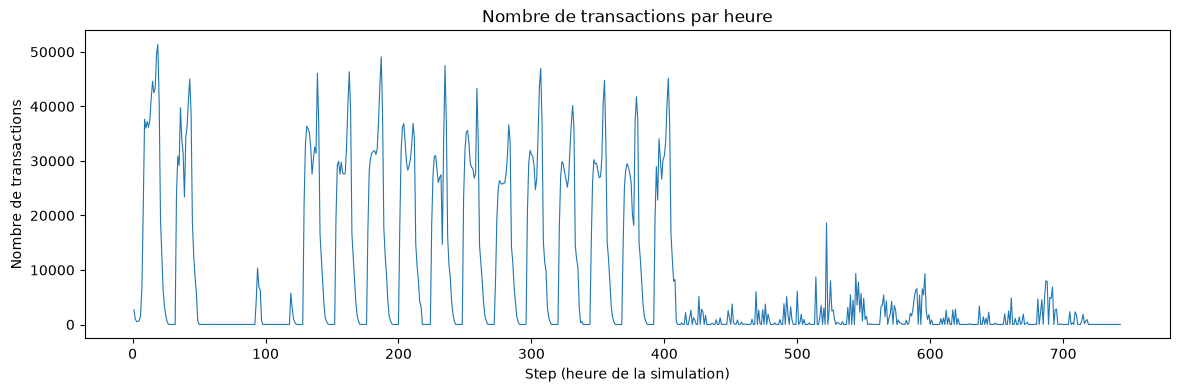

In [5]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(par_step["step"], par_step["transactions"], linewidth=0.8)
ax.set_xlabel("Step (heure de la simulation)")
ax.set_ylabel("Nombre de transactions")
ax.set_title("Nombre de transactions par heure")
plt.show()

In [6]:
con.sql("""
    SELECT (step - 1) // 24 + 1 AS jour, COUNT(*) AS transactions
    FROM transactions
    GROUP BY jour
    ORDER BY jour
""").pl()

jour,transactions
i32,i64
1,574255
2,455238
3,1070
4,28240
5,9789
6,441005
7,420583
8,449637
9,417919


In [7]:
con.sql("""
    SELECT (step - 1) % 24 AS heure_du_jour, COUNT(*) AS transactions
    FROM transactions
    GROUP BY heure_du_jour
    ORDER BY heure_du_jour
""").pl()

heure_du_jour,transactions
i32,i64
0,27111
1,9018
2,2007
3,1241
4,1641
5,3420
6,8988
7,26915
8,283518


In [8]:
con.sql("""
    WITH par_step AS (
        SELECT step, COUNT(*) AS transactions
        FROM transactions
        GROUP BY step
    ),
    cumul AS (
        SELECT
            step,
            transactions,
            SUM(transactions) OVER (ORDER BY step) AS cumul,
            SUM(transactions) OVER () AS total
        FROM par_step
    )
    SELECT step, transactions, cumul, ROUND(100.0 * cumul / total, 2) AS part_cumulee_pct
    FROM cumul
    WHERE cumul >= 0.80 * total
    ORDER BY step
    LIMIT 3
""").pl()

step,transactions,cumul,part_cumulee_pct
i32,i64,"decimal[38,0]",f64
355,44787,5113884,80.37
356,33528,5147412,80.9
357,15096,5162508,81.14
